In [8]:
!pip install -q ultralytics opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.8 MB/s eta 0:00:00


In [9]:
import torch
import cv2
import ultralytics

print("YOLO version:", ultralytics.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO version: 8.4.183
OpenCV version: 4.14.0
GPU available: False


In [10]:
from ultralytics import YOLO

# Load a small pretrained YOLO model
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [11]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [12]:


!pip install -q kaggle

import os
import shutil

# Create a folder for Kaggle credentials
os.makedirs("/root/.kaggle", exist_ok=True)

# Copy the uploaded key into that folder
shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

# Protect the credentials file
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle configured successfully!")



Kaggle configured successfully!


In [14]:


!mkdir -p /content/drone_dataset

!kaggle datasets download \
    -d cybersimar08/drone-detection \
    -p /content/drone_dataset \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/cybersimar08/drone-detection
License(s): CC0-1.0
100% 499M/499M [00:05<00:00, 98.2MB/s]



In [15]:


import os

dataset_path = "/content/drone_dataset"

print("Dataset folder exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:10]:
            print("  " * (level + 1) + file)

Dataset folder exists: True
drone_dataset/
  coco json drone detection/
    README.dataset.txt
    README.roboflow.txt
    valid/
      V_HELICOPTER_038262_273_png.rf.a5066fed0a7933a471285a34c85ff274.jpg
      V_BIRD_02988_192_png.rf.51be39b79751007d1222884e3d3b6de7.jpg
      V_HELICOPTER_015239_177_png.rf.575e3ad09d08165b6641907ffb9835c8.jpg
      V_AIRPLANE_0033_291_png.rf.8583d41b433cc84b6b457d24eb5553ea.jpg
      V_DRONE_008118_285_png.rf.0fdd4d119a8e7af724023c5cab036f11.jpg
      V_DRONE_016126_282_png.rf.467dc0c66b0fb3c4f6b29cb170094dd5.jpg
      V_AIRPLANE_01313_041_png.rf.26fe599d369f0873494258e872b09cc4.jpg
      V_BIRD_050109_262_png.rf.a4e65f05a52477d4571ca3372dc914fd.jpg
      V_DRONE_112222_223_png.rf.5f715f52c72972fb44566e7f3bf1fb13.jpg
      V_HELICOPTER_050274_192_png.rf.c8dae66c2abc17985bc2888a062902dd.jpg
    train/
      V_DRONE_003113_074_png.rf.93f8a3feaa9daff2d0f6dd48bbf5bfff.jpg
      V_BIRD_01170_143_png.rf.4f600e54754362b09decf97c1087f770.jpg
      V_BIRD_03796

In [16]:

import os

dataset_root = "/content/drone_dataset"

for root, dirs, files in os.walk(dataset_root):
    if "data.yaml" in files:
        print("Found YOLO configuration:")
        print(os.path.join(root, "data.yaml"))


Found YOLO configuration:
/content/drone_dataset/drone-detection-new.v5-new-train.yolov8/data.yaml


In [17]:

import yaml

yaml_path = (
    "/content/drone_dataset/"
    "drone-detection-new.v5-new-train.yolov8/data.yaml"
)

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print(config)


{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['AirPlane', 'Drone', 'Helicopter'], 'roboflow': {'workspace': 'ahmedmohsen', 'project': 'drone-detection-new-peksv', 'version': 5, 'license': 'MIT', 'url': 'https://universe.roboflow.com/ahmedmohsen/drone-detection-new-peksv/dataset/5'}}


In [18]:


import yaml
import os

dataset_dir = (
    "/content/drone_dataset/"
    "drone-detection-new.v5-new-train.yolov8"
)

fixed_config = {
    "path": dataset_dir,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 3,
    "names": ["AirPlane", "Drone", "Helicopter"]
}

fixed_yaml = "/content/drone_data.yaml"

with open(fixed_yaml, "w") as f:
    yaml.safe_dump(fixed_config, f, sort_keys=False)

print("Corrected configuration:")
print(open(fixed_yaml).read())


Corrected configuration:
path: /content/drone_dataset/drone-detection-new.v5-new-train.yolov8
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- AirPlane
- Drone
- Helicopter



In [19]:


import os

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_dir, split, "images")
    label_dir = os.path.join(dataset_dir, split, "labels")

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    print(f"{split}:")
    print("  Images:", len(images))
    print("  Label files:", len(labels))



train:
  Images: 10799
  Label files: 10799
valid:
  Images: 603
  Label files: 603
test:
  Images: 596
  Label files: 596


In [20]:

from ultralytics import YOLO

# Load a small pretrained YOLO model
model = YOLO("yolo11n.pt")

# Train it on the drone dataset
results = model.train(
    data=fixed_yaml,
    epochs=5,
    imgsz=640,
    batch=4,
    device="cpu",
    patience=8,
    project="/content/drone_runs",
    name="drone_detection_v2"
)


Ultralytics 8.4.183 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drone_data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_detection_v2, nbs=64, nms=None, opset=None, optimize=Fals

KeyboardInterrupt: 

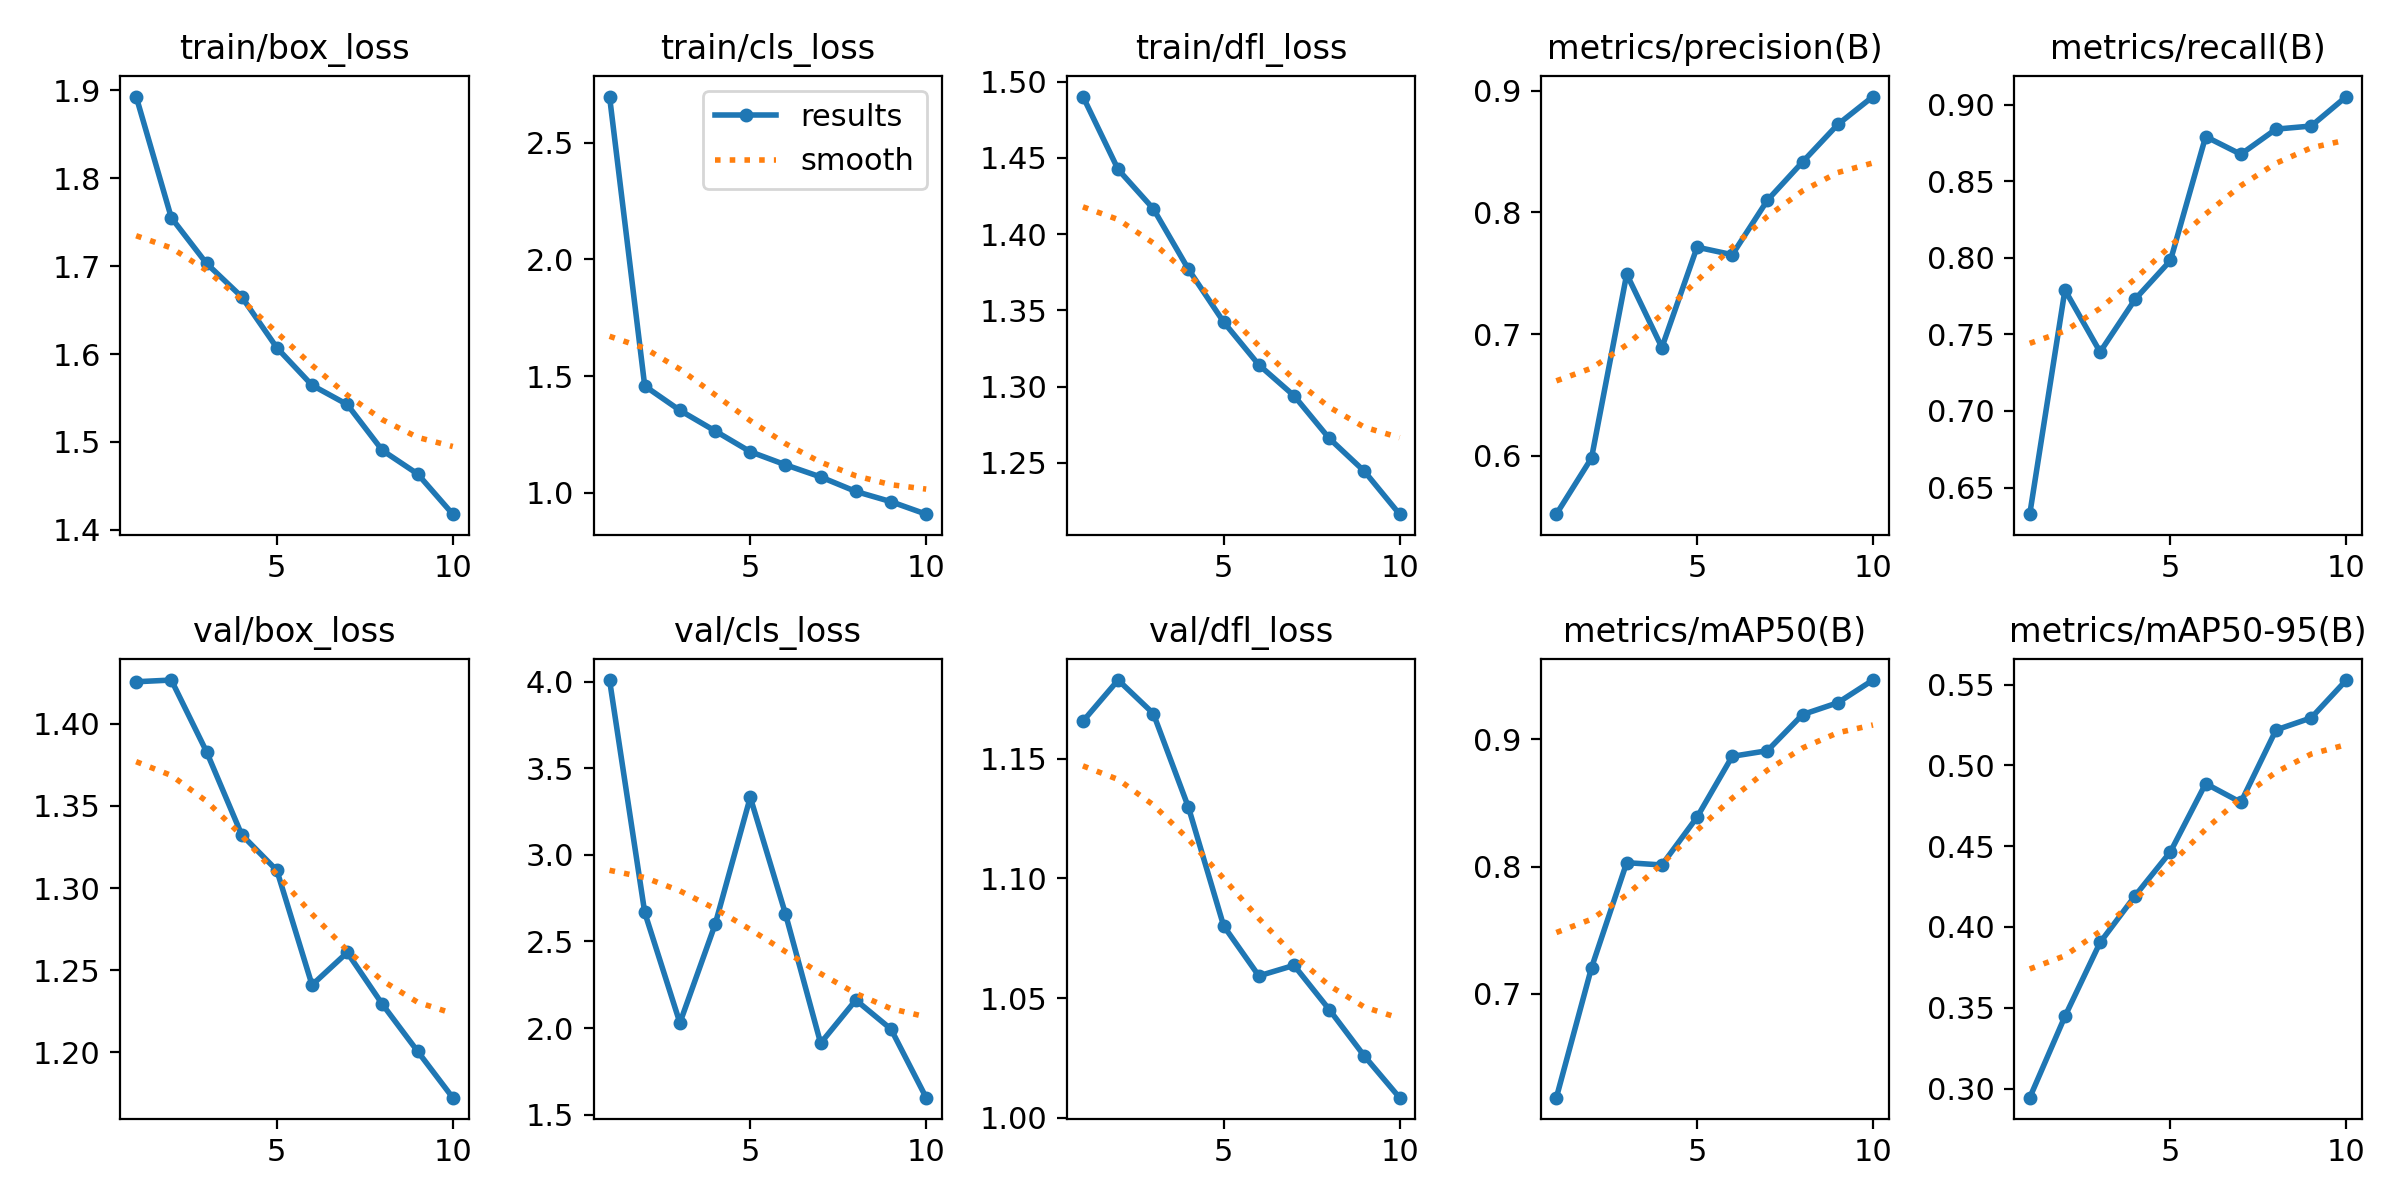

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/drone_runs/drone_detection/results.png"))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
import shutil

source = "/content/drone_runs/drone_detection/weights/best.pt"
destination = "/content/drive/MyDrive/best.pt"

shutil.copy2(source, destination)

print("Model saved:", os.path.exists(destination))
print("Model size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drone_runs/drone_detection/weights/best.pt'

In [4]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/best.pt")

print("Model loaded successfully!")
print("Classes:", model.names)


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-10-19 at 8.01.54 PM.png to Screenshot 2026-10-19 at 8.01.54 PM.png


In [3]:
from IPython.display import display, Image
import glob
import os

import os
from IPython.display import display, Image

image_path = next(iter(uploaded.keys()))

results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)
saved_images = glob.glob("/content/runs/detect/predict/*")

print("Saved files:", saved_images)

if saved_images:
    display(Image(filename=saved_images[0]))

NameError: name 'uploaded' is not defined

In [1]:
from google.colab import files

uploaded_video = files.upload()

Saving 27363-363524166.mp4 to 27363-363524166.mp4


In [2]:
import os
from ultralytics import YOLO

# Load your trained model from Google Drive
model = YOLO("/content/drive/MyDrive/best.pt")

# Get the uploaded video filename
video_path = next(iter(uploaded_video.keys()))

# Track objects throughout the video
results = model.track(
    source=video_path,
    conf=0.25,
    tracker="bytetrack.yaml",
    persist=True,
    save=True,
    project="/content/drone_tracking",
    name="tracked_video"
)

print("Tracking finished!")

ModuleNotFoundError: No module named 'ultralytics'